Here I created embedding on collab GPU, no need to run this cell, I already sent it to you on email. Everything that we need needs to be in data/artifacts.


Note: I appended title with the paragraph for embedding to gain a bit of context

In [ ]:
# import os
# import json
# import numpy as np
# import pandas as pd
# from sentence_transformers import SentenceTransformer

# # 1. POINT EXPLICITLY TO YOUR UPLOADED FILE LOCATIONS
# # Change your paths to this:
# NODES_PATH = "/content/nodes.parquet"       
# QUESTIONS_PATH = "/content/questions.parquet"

# print("Reading data tables out of /content/rl/...")
# docs_df = pd.read_parquet(NODES_PATH)
# queries_df = pd.read_parquet(QUESTIONS_PATH)
# print(f"Loaded {len(docs_df)} documents and {len(queries_df)} queries successfully!")

# # Format your text column like this before running encode_texts:
# docs_df["title_text"] = docs_df["title"] + " - " + docs_df["text"]

# # 2. EMBEDDING ENGINE SETUP
# def _freeze_hash(df):
#     # Deterministic contract hash to tie embeddings to this exact corpus snapshot
#     return str(hash(tuple(df["node_id"].tolist())))

# def encode_texts(model, texts, batch_size=256, instruction=None):
#     if instruction:
#         texts = [instruction + t for t in texts]
#     emb = model.encode(
#         texts, 
#         batch_size=batch_size, 
#         normalize_embeddings=True, # Allows downstream fast dot-product instead of full cosine math
#         show_progress_bar=True, 
#         convert_to_numpy=True
#     )
#     return np.ascontiguousarray(emb, dtype=np.float32)

# # Load the model directly into Colab's active CUDA GPU hardware
# print("\nInitializing BGE Model on Cloud GPU...")
# model = SentenceTransformer("BAAI/bge-base-en-v1.5", device="cuda")

# print("Encoding master corpus documents...")
# doc_emb = encode_texts(model, docs_df["title_text"].tolist())

# print("Encoding queries...")
# query_emb = encode_texts(
#     model, 
#     queries_df["query_text"].tolist(), 
#     instruction="Represent this sentence for searching relevant passages: "
# )

# query_ids = queries_df["question_id"].to_numpy().astype(str)

# manifest = dict(
#     model_name="BAAI/bge-base-en-v1.5", 
#     dim=int(doc_emb.shape[1]), 
#     n_docs=int(doc_emb.shape[0]),
#     n_queries=int(query_emb.shape[0]), 
#     normalized=True, 
#     query_instruction="Represent this sentence for searching relevant passages: ",
#     corpus_node_id_hash=_freeze_hash(docs_df)
# )

# # 3. WRITE ARTIFACTS TEMPORARILY TO THE CLOUD DRIVE
# print("\nWriting generated matrices to temporary cloud storage...")
# OUTPUT_DIR = "/content/rl/artifacts"
# os.makedirs(OUTPUT_DIR, exist_ok=True)

# np.save(f"{OUTPUT_DIR}/doc_emb.npy", doc_emb)
# np.save(f"{OUTPUT_DIR}/query_emb.npy", query_emb)
# np.save(f"{OUTPUT_DIR}/query_ids.npy", query_ids)

# with open(f"{OUTPUT_DIR}/embeddings_manifest.json", "w") as f:
#     json.dump(manifest, f, indent=2)

# print(f"🎉 Matrix compilation complete! Vectors saved to: {OUTPUT_DIR}")

Reading data tables out of /content/rl/...
Loaded 101962 documents and 22355 queries successfully!

Initializing BGE Model on Cloud GPU...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:122: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.6k [00:00<?, ?B/s]

...

Encoding master corpus documents...


Batches:   0%|          | 0/399 [00:00<?, ?it/s]

Encoding queries...


Batches:   0%|          | 0/88 [00:00<?, ?it/s]


Writing generated matrices to temporary cloud storage...
🎉 Matrix compilation complete! Vectors saved to: /content/rl/artifacts


# a little bit of EDA for embeddings

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. LOAD THE DATA AND FRESHLY GENERATED EMBEDDING ARTIFACTS
ARTIFACTS_DIR = "../data/artifacts"
NODES_PATH = "../data/interim/nodes.parquet"       
QUESTIONS_PATH = "../data/interim/questions.parquet"

docs_df = pd.read_parquet(NODES_PATH)
queries_df = pd.read_parquet(QUESTIONS_PATH)

doc_emb = np.load(f"{ARTIFACTS_DIR}/doc_emb.npy")
query_emb = np.load(f"{ARTIFACTS_DIR}/query_emb.npy")
query_ids = np.load(f"{ARTIFACTS_DIR}/query_ids.npy")

In [2]:
doc_emb.shape

(101962, 768)

In [3]:
query_emb.shape

(22355, 768)

In [4]:
query_ids.shape

(22355,)

In [5]:
queries_df.head(1)

,question_id,split,query_text,n_hops,gold_node_ids,candidate_node_ids,answer
0,3hop1__614774_42467_91253,train,What is the period of revolution of the planet...,3,"[19, 11, 7]","[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...",88 days


Analyzing dense vector similarities across candidate pools...


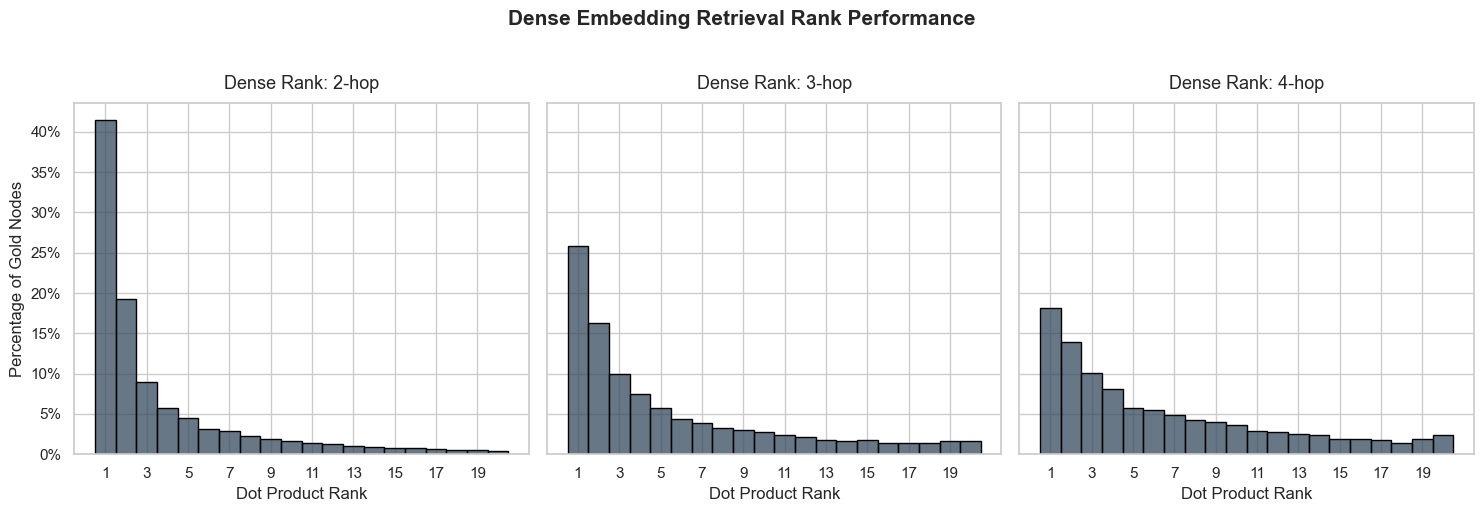

In [6]:
# Create lookup mappings
node_id_to_idx = {node_id: idx for idx, node_id in enumerate(docs_df["node_id"])}
query_id_to_idx = {qid: idx for idx, qid in enumerate(query_ids)}

# ---------------------------------------------------------------------------
# DIAGNOSTIC 1: COMPUTE RANKS PER N-HOP CATEGORY
# ---------------------------------------------------------------------------
ranks_records = []
gold_scores = []
distractor_scores = []

print("Analyzing dense vector similarities across candidate pools...")
for _, row in queries_df.iterrows():
    q_id = str(row["question_id"])
    if q_id not in query_id_to_idx:
        continue
        
    n_hops = row["n_hops"]
    gold_ids = set(row["gold_node_ids"])
    candidate_ids = row["candidate_node_ids"]
    
    # Extract the pre-computed query vector
    q_idx = query_id_to_idx[q_id]
    v_query = query_emb[q_idx] # Shape: (768,)
    
    # Gather matching cloud indices for the candidates
    cand_matrix_indices = [node_id_to_idx[cid] for cid in candidate_ids if cid in node_id_to_idx]
    if not cand_matrix_indices:
        continue
        
    # Extract candidate document vectors
    v_candidates = doc_emb[cand_matrix_indices] # Shape: (N_candidates, 768)
    
    # MATHEMATICAL WIN: Because your vectors are unit-normalized to length 1,
    # Cosine Similarity is calculated instantly via a basic matrix-vector Dot Product!
    sim_scores = np.dot(v_candidates, v_query) 
    
    # Map candidate IDs to their dot-product similarity score
    cand_to_score = {cid: score for cid, score in zip(candidate_ids, sim_scores)}
    
    # Store scores for Gold vs Distractor analysis
    for cid, score in zip(candidate_ids, sim_scores):
        if cid in gold_ids:
            gold_scores.append(score)
        else:
            distractor_scores.append(score)
            
    # Calculate exact dense ranks for each gold answer node
    for gold_id in gold_ids:
        if gold_id in cand_to_score:
            gold_score = cand_to_score[gold_id]
            # Rank = 1 + how many candidates beat the gold score
            rank = np.sum(sim_scores > gold_score) + 1
            ranks_records.append({"n_hops": n_hops, "rank": rank})

ranks_df = pd.DataFrame(ranks_records)

# ---------------------------------------------------------------------------
# PLOT 1: SIDE-BY-SIDE N-HOP RANK HISTOGRAMS (WITH PERCENTAGES)
# ---------------------------------------------------------------------------
sns.set_theme(style="whitegrid")
hop_groups = sorted(ranks_df["n_hops"].unique())

fig, axes = plt.subplots(1, len(hop_groups), figsize=(5 * len(hop_groups), 5), sharey=True)
if len(hop_groups) == 1:
    axes = [axes]

for ax, hop in zip(axes, hop_groups):
    subset = ranks_df[ranks_df["n_hops"] == hop]
    
    sns.histplot(
        data=subset, 
        x="rank", 
        bins=np.arange(0.5, 21.5, 1),
        stat="percent", # 👈 Changes the calculation from absolute Count to Percentage
        ax=ax, 
        kde=False, 
        color="#34495e", 
        edgecolor="black"
    )
    
    ax.set_title(f"Dense Rank: {hop}-hop", fontsize=13, pad=10)
    ax.set_xlabel("Dot Product Rank")
    ax.set_xticks(range(1, 21, 2))
    
    # Format the y-tick labels dynamically to append a '%' sign
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0f}%'))

# Adjust the shared y-axis label on the leftmost plot to reflect the change
axes[0].set_ylabel("Percentage of Gold Nodes", fontsize=12)

plt.suptitle("Dense Embedding Retrieval Rank Performance", y=1.02, fontsize=15, weight='bold')
plt.tight_layout()
plt.show()

roughly in 50% of the cases the cos similarity does not cut it

In [7]:
def evaluate_cumulative_baseline(a: dict, n: int = 500, split: str = "validation", max_k: int = 20) -> pd.DataFrame:
    """
    Globally retrieves top docs by cosine similarity and computes 
    cumulative Recall@K metrics from K=1 up to max_k.
    """
    qs  = a["questions"]
    # Filter by split and sample standardly
    val = qs[qs["split"] == split].sample(
        n=min(n, (qs["split"] == split).sum()),
        random_state=42,
    )
    
    # We need the lookup mapping to convert gold string IDs to matrix row indices
    # Assumes node_id_to_idx is passed inside 'a' or is globally accessible
    node_to_idx = a.get("node_id_to_idx", node_id_to_idx)
    
    recall_records = []
    
    for _, row in val.iterrows():
        qid = row["question_id"]
        if qid not in a["qid_to_qi"]:
            continue
            
        # Keep track of n_hops so you can still break down performance by complexity
        n_hops = row.get("n_hops", "Unknown")
        
        # Convert gold node string IDs into their respective embedding matrix row indices
        gold_indices = {node_to_idx[gid] for gid in row["gold_node_ids"] if gid in node_to_idx}
        if not gold_indices:
            continue
            
        qi      = a["qid_to_qi"][qid]
        q_norm  = a["query_emb"][qi]
        
        # 1. GLOBAL SCAN: Calculate dot product across the entire corpus
        sims    = a["doc_emb"] @ q_norm
        
        # 2. SORT ONCE: Grab the top indices up to your maximum K target
        global_top_indices = np.argsort(sims)[::-1][:max_k].tolist()
        
        # 3. CUMULATIVE STEPPING: Evaluate intersection for every K from 1 to max_k
        for k in range(1, max_k + 1):
            retrieved_at_k = set(global_top_indices[:k])
            hits = len(retrieved_at_k & gold_indices)
            recall_at_k = hits / len(gold_indices)
            
            recall_records.append({
                "question_id": qid,
                "n_hops": n_hops,
                "k": k,
                "recall": recall_at_k
            })
            
    return pd.DataFrame(recall_records)

In [8]:
from src.rl import load_artifacts

a = load_artifacts()

/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading artifacts ...


In [11]:
# 1. Run the evaluation
# (Make sure to add your lookup dictionary to 'a' if it isn't global)
a["node_id_to_idx"] = node_id_to_idx 
cumulative_results_df = evaluate_cumulative_baseline(a, n=500, split="validation", max_k=100)

# 2. Aggregate to find the global average Recall@K across all sampled queries
global_recall_summary = cumulative_results_df.groupby("k")["recall"].mean().reset_index()
global_recall_summary["recall_percentage"] = global_recall_summary["recall"] * 100

print("--- Global Cumulative Recall Breakdown ---")
print(global_recall_summary[['k', 'recall_percentage']].to_string(index=False))

# 3. Optional: Break it down by N-Hops to see if multi-hop queries decay faster
hop_recall_summary = cumulative_results_df.groupby(["n_hops", "k"])["recall"].mean().reset_index()

--- Global Cumulative Recall Breakdown ---
  k  recall_percentage
  1          25.150000
  2          33.533333
  3          37.916667
  4          41.233333
  5          43.100000
  6          44.716667
  7          46.350000
  8          47.216667
  9          48.100000
 10          49.233333
 11          49.950000
 12          50.566667
 13          51.450000
 14          52.333333
 15          52.966667
 16          53.783333
 17          54.633333
 18          55.183333
 19          55.900000
 20          56.433333
 21          56.850000
 22          57.450000
 23          58.316667
 24          59.000000
 25          59.183333
 26          59.516667
 27          59.900000
 28          60.216667
 29          60.500000
 30          60.816667
 31          61.050000
 32          61.400000
 33          61.500000
 34          61.966667
 35          62.066667
 36          62.183333
 37          62.716667
 38          63.033333
 39          63.300000
 40          63.366667
 41          6

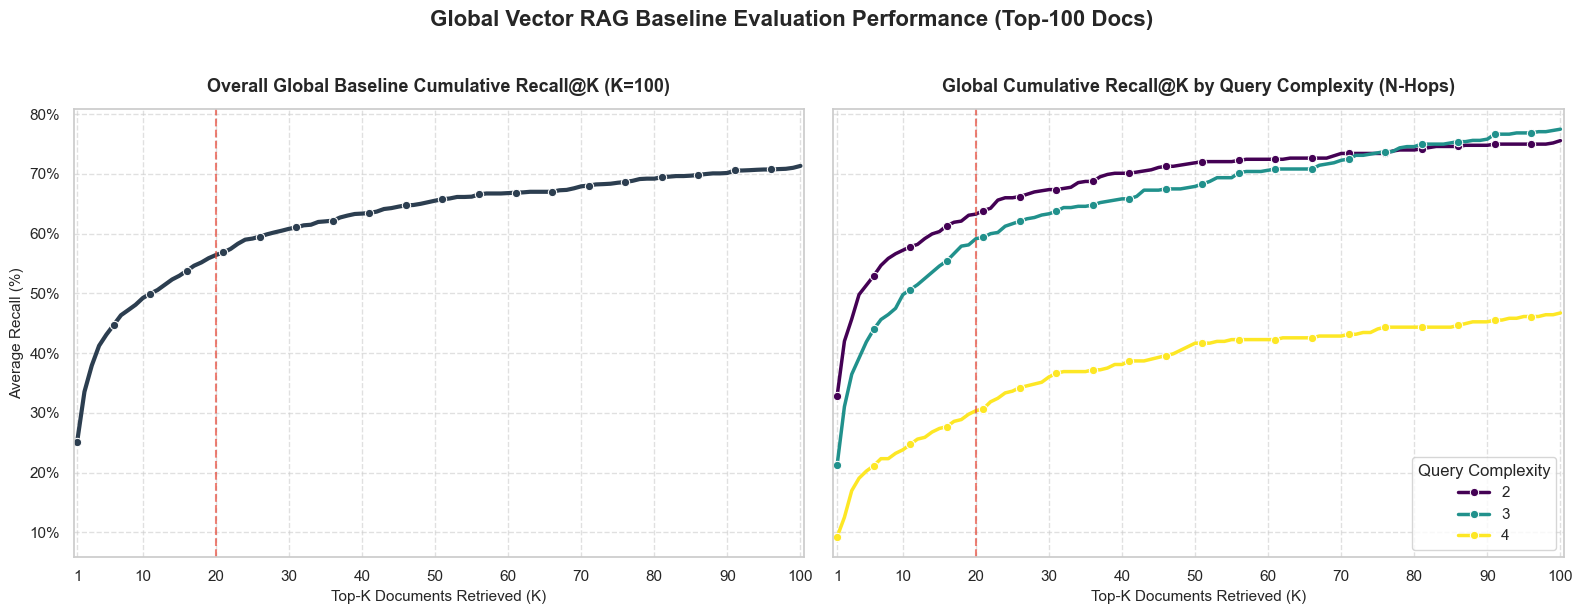

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------------------------------------------------------------------
# 1. PREPARE AND AGGREGATE EVALUATION DATA (max_k=100)
# ---------------------------------------------------------------------------
# (Your data preparation stays exactly the same)
cumulative_results_df = evaluate_cumulative_baseline(a, n=500, split="validation", max_k=100)

overall_recall = cumulative_results_df.groupby("k")["recall"].mean().reset_index()
overall_recall["recall_pct"] = overall_recall["recall"] * 100

hop_recall = cumulative_results_df.groupby(["n_hops", "k"])["recall"].mean().reset_index()
hop_recall["recall_pct"] = hop_recall["recall"] * 100

# ---------------------------------------------------------------------------
# 2. PLOT SIDE-BY-SIDE CUMULATIVE RECALL CURVES (K up to 100)
# ---------------------------------------------------------------------------
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# Define clean x-tick intervals for K=1 to 100 (steps of 10)
x_ticks_100 = [1] + list(range(10, 101, 10))

# --- AXIS 1: Overall Global Baseline Performance ---
sns.lineplot(
    data=overall_recall,
    x="k",
    y="recall_pct",
    marker="o",
    markevery=5, # 💡 Only draw dots every 5 steps to keep the line clean
    linewidth=3,
    color="#2c3e50",
    ax=axes[0]
)
axes[0].set_title("Overall Global Baseline Cumulative Recall@K (K=100)", fontsize=13, pad=12, weight="bold")
axes[0].set_xlabel("Top-K Documents Retrieved (K)", fontsize=11)
axes[0].set_ylabel("Average Recall (%)", fontsize=11)
axes[0].set_xticks(x_ticks_100) # Clean x-ticks

# --- AXIS 2: Stratified Performance by N-Hops ---
sns.lineplot(
    data=hop_recall,
    x="k",
    y="recall_pct",
    hue="n_hops",
    marker="o",
    markevery=5, # 💡 Keep marker density clean across multi-line views
    linewidth=2.5,
    palette="viridis",
    ax=axes[1]
)
axes[1].set_title("Global Cumulative Recall@K by Query Complexity (N-Hops)", fontsize=13, pad=12, weight="bold")
axes[1].set_xlabel("Top-K Documents Retrieved (K)", fontsize=11)
axes[1].set_ylabel("") # Hidden due to sharey=True
axes[1].set_xticks(x_ticks_100) # Clean x-ticks
axes[1].legend(title="Query Complexity", loc="lower right", frameon=True)

# --- GLOBAL STYLING ADJUSTMENTS ---
for ax in axes:
    # Set standard integer percentage formatting on the y-axis
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0f}%'))
    
    # Bound the chart strictly from K=1 to K=100
    ax.set_xlim(0.5, 100.5)
    
    # Keep a vertical indicator highlighting the standard RAG baseline benchmark (K=20)
    ax.axvline(x=20, color="#e74c3c", linestyle="--", alpha=0.7, label="RAG Cutoff (K=20)")
    ax.grid(True, linestyle="--", alpha=0.6)

plt.suptitle("Global Vector RAG Baseline Evaluation Performance (Top-100 Docs)", y=1.02, fontsize=16, weight="bold")
plt.tight_layout()
plt.show()

In [33]:
nodes_df = pd.read_parquet('../data/interim/nodes.parquet')
nodes_df.head(4)

,node_id,title,text,freq
0,0,History of gravitational theory,"In 1687, English mathematician Sir Isaac Newto...",6
1,1,C/2014 G3,C/2014 G3 is a faint comet discovered on 10 Ap...,1
2,2,Neptune,Neptune is not visible to the unaided eye and ...,12
3,3,227 Philosophia,Philosophia (minor planet designation: 227 Phi...,1


In [37]:
nodes_df['text'].str.split().str.len().describe()

count    101962.000000
mean         73.274141
std          45.700243
min          19.000000
25%          39.000000
50%          61.000000
75%          95.000000
max         299.000000
Name: text, dtype: float64

In [41]:
nodes_df['text'].str.split().str.len().quantile(0.995)

np.float64(256.0)

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from sentence_transformers import CrossEncoder

sns.set_theme(style="whitegrid")

In [58]:
device = "mps" if torch.backends.mps.is_available() else "cpu"
print(f"Using device: {device}")

reranker = CrossEncoder(
    "BAAI/bge-reranker-base",
    device=device,
    max_length=256,
    model_kwargs={"torch_dtype": torch.float16} if device == "mps" else {},
)

# Warm up so MPS kernel compilation isn't counted into your first real query
_ = reranker.predict([("warmup", "warmup document text")] * 8, batch_size=8)
print("Reranker ready.")

Using device: mps


Loading weights: 100%|██████████| 201/201 [00:01<00:00, 140.21it/s]


Reranker ready.


In [59]:
import time

probe = [("query text", "some candidate document text here")] * 512
t0 = time.perf_counter()
_ = reranker.predict(probe, batch_size=128)
dt = time.perf_counter() - t0
print(f"{dt:.2f}s for 512 pairs -> {1000*dt/512:.1f} ms/pair")

1.66s for 512 pairs -> 3.2 ms/pair


In [60]:
def evaluate_cumulative_reranked_baseline(
    a, reranker, n=500, split="validation", max_k=20, pool=50, rerank_batch=128
):
    qs = a["questions"]
    val = qs[qs["split"] == split].sample(
        n=min(n, int((qs["split"] == split).sum())), random_state=42
    )

    node_to_idx = a.get("node_id_to_idx")
    idx_to_node = {v: k for k, v in node_to_idx.items()} if node_to_idx else None

    # Keep only usable rows (valid qid, non-empty gold set)
    rows = [
        r for _, r in val.iterrows()
        if r["question_id"] in a["qid_to_qi"] and len(r["gold_node_ids"]) > 0
    ]
    print(f"Evaluating {len(rows)} queries from '{split}'...")

    # ── STAGE 1: vectorized dense retrieval for ALL queries at once ──
    qis = np.array([a["qid_to_qi"][r["question_id"]] for r in rows])
    Q = a["query_emb"][qis]                 # (nq, d)
    sims = a["doc_emb"] @ Q.T               # (ndocs, nq)

    # top-`pool` per query via argpartition (no full sort)
    part = np.argpartition(-sims, pool, axis=0)[:pool]   # (pool, nq), unordered
    cand_per_query = []
    for j in range(len(rows)):
        col = part[:, j]
        col = col[np.argsort(-sims[col, j])]             # order this query's pool
        cand_per_query.append(col.tolist())

    # ── STAGE 2: build ALL (query, doc) pairs, rerank in big batches ──
    flat_pairs, offsets = [], []
    for r, cands in zip(rows, cand_per_query):
        offsets.append((len(flat_pairs), len(flat_pairs) + len(cands)))
        flat_pairs.extend((r["query_text"], a["doc_texts"][d]) for d in cands)

    scores = reranker.predict(flat_pairs, batch_size=rerank_batch, show_progress_bar=True)

    # ── STAGE 3: per-query cumulative recall@k ──
    records = []
    for r, cands, (lo, hi) in zip(rows, cand_per_query, offsets):
        s = scores[lo:hi]
        ranked = [c for c, _ in sorted(zip(cands, s), key=lambda x: x[1], reverse=True)][:max_k]
        if idx_to_node and isinstance(r["gold_node_ids"][0], str):
            ranked = [idx_to_node[i] for i in ranked if i in idx_to_node]

        gold = set(r["gold_node_ids"])
        for k in range(1, max_k + 1):
            hits = len(set(ranked[:k]) & gold)
            records.append({
                "question_id": r["question_id"],
                "n_hops": r.get("n_hops", "Unknown"),
                "k": k,
                "recall": hits / len(gold),
            })
    return pd.DataFrame(records)

In [66]:
reranked_results_df = evaluate_cumulative_reranked_baseline(
    a=a,
    reranker=reranker,
    n=500,
    split="validation",
    max_k=20,
    pool=100,          # dense candidate pool size before reranking
    rerank_batch=128,
)

overall_summary = reranked_results_df.groupby("k")["recall"].mean().reset_index()
overall_summary["recall_pct"] = overall_summary["recall"] * 100

print("\n--- Two-Stage Reranked Baseline Recall ---")
print(overall_summary[["k", "recall_pct"]].to_string(index=False))

Evaluating 500 queries from 'validation'...


Batches: 100%|██████████| 391/391 [09:12<00:00,  1.41s/it]



--- Two-Stage Reranked Baseline Recall ---
 k  recall_pct
 1   28.516667
 2   37.666667
 3   41.716667
 4   44.983333
 5   46.716667
 6   48.333333
 7   49.683333
 8   50.666667
 9   51.600000
10   52.366667
11   53.183333
12   53.850000
13   54.750000
14   55.116667
15   55.650000
16   56.150000
17   56.700000
18   57.166667
19   57.483333
20   57.966667


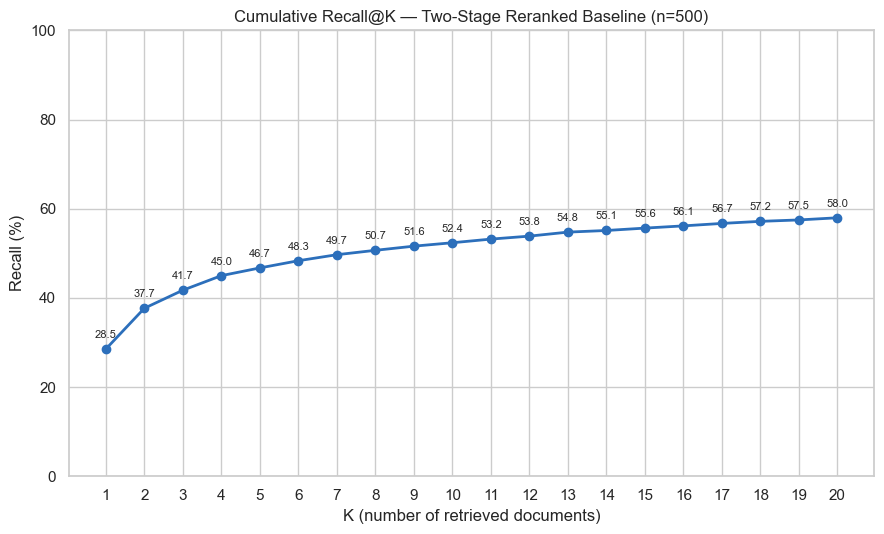

In [67]:
plt.figure(figsize=(9, 5.5))

plt.plot(
    overall_summary["k"],
    overall_summary["recall_pct"],
    marker="o",
    linewidth=2,
    color="#2c6fbb",
)

for _, r in overall_summary.iterrows():
    plt.annotate(f"{r['recall_pct']:.1f}",
                 (r["k"], r["recall_pct"]),
                 textcoords="offset points", xytext=(0, 8),
                 ha="center", fontsize=8)

plt.title(f"Cumulative Recall@K — Two-Stage Reranked Baseline (n={reranked_results_df['question_id'].nunique()})")
plt.xlabel("K (number of retrieved documents)")
plt.ylabel("Recall (%)")
plt.xticks(range(1, 21))
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

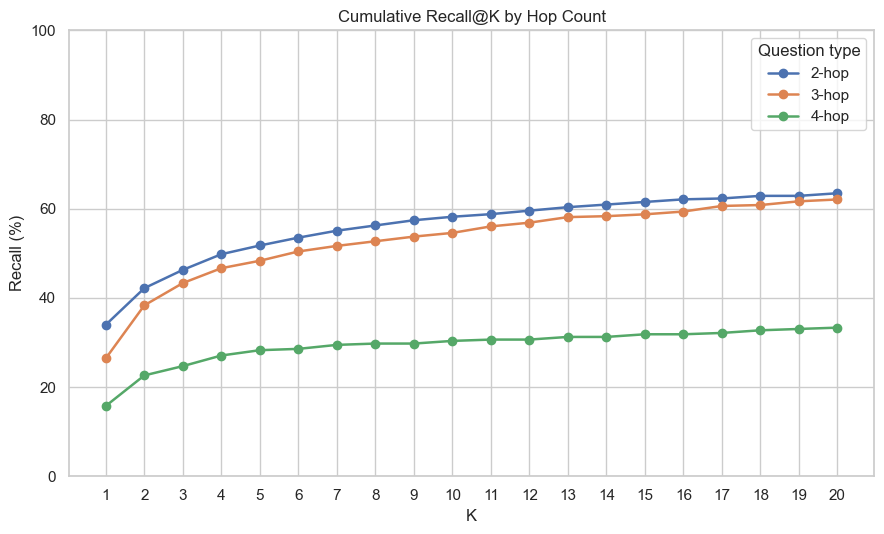

In [68]:
by_hops = (
    reranked_results_df.groupby(["n_hops", "k"])["recall"]
    .mean().mul(100).reset_index(name="recall_pct")
)

plt.figure(figsize=(9, 5.5))
for hop, grp in by_hops.groupby("n_hops"):
    plt.plot(grp["k"], grp["recall_pct"], marker="o", linewidth=1.8, label=f"{hop}-hop")

plt.title("Cumulative Recall@K by Hop Count")
plt.xlabel("K")
plt.ylabel("Recall (%)")
plt.xticks(range(1, 21))
plt.ylim(0, 100)
plt.legend(title="Question type")
plt.tight_layout()
plt.show()

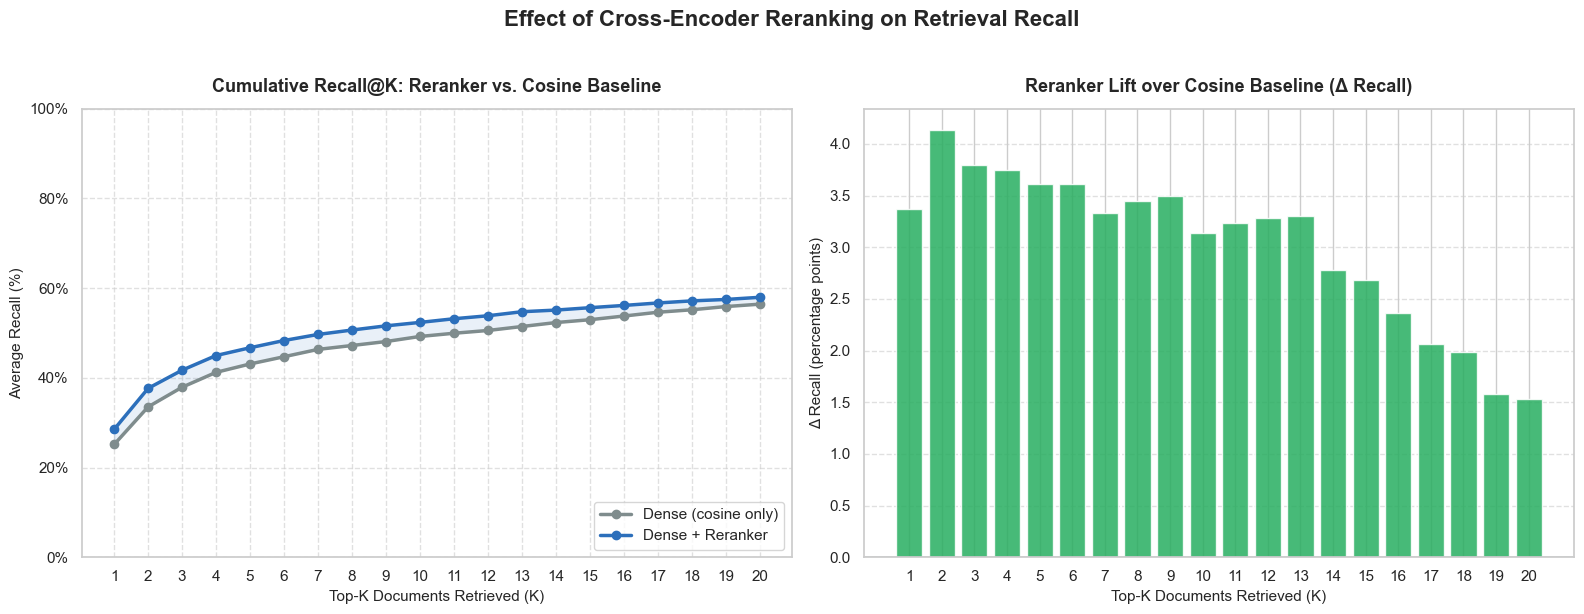

K | Dense% | Rerank% | Δpp
 1 |   25.1 |    28.5 |  +3.4
 2 |   33.5 |    37.7 |  +4.1
 3 |   37.9 |    41.7 |  +3.8
 4 |   41.2 |    45.0 |  +3.8
 5 |   43.1 |    46.7 |  +3.6
 6 |   44.7 |    48.3 |  +3.6
 7 |   46.4 |    49.7 |  +3.3
 8 |   47.2 |    50.7 |  +3.5
 9 |   48.1 |    51.6 |  +3.5
10 |   49.2 |    52.4 |  +3.1
11 |   50.0 |    53.2 |  +3.2
12 |   50.6 |    53.8 |  +3.3
13 |   51.4 |    54.8 |  +3.3
14 |   52.3 |    55.1 |  +2.8
15 |   53.0 |    55.6 |  +2.7
16 |   53.8 |    56.1 |  +2.4
17 |   54.6 |    56.7 |  +2.1
18 |   55.2 |    57.2 |  +2.0
19 |   55.9 |    57.5 |  +1.6
20 |   56.4 |    58.0 |  +1.5


In [69]:
sns.set_theme(style="whitegrid")

MAX_K = 20  # reranker was evaluated up to here

# --- Aggregate both pipelines to overall mean recall (%) ---
dense_overall = (
    cumulative_results_df[cumulative_results_df["k"] <= MAX_K]
    .groupby("k")["recall"].mean().mul(100).reset_index(name="recall_pct")
)
rerank_overall = (
    reranked_results_df[reranked_results_df["k"] <= MAX_K]
    .groupby("k")["recall"].mean().mul(100).reset_index(name="recall_pct")
)

# --- Merge for the delta panel ---
comp = dense_overall.merge(rerank_overall, on="k", suffixes=("_dense", "_rerank"))
comp["delta"] = comp["recall_pct_rerank"] - comp["recall_pct_dense"]

# ---------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- AXIS 1: Overlaid recall curves ---
axes[0].plot(dense_overall["k"], dense_overall["recall_pct"],
             marker="o", linewidth=2.5, color="#7f8c8d", label="Dense (cosine only)")
axes[0].plot(rerank_overall["k"], rerank_overall["recall_pct"],
             marker="o", linewidth=2.5, color="#2c6fbb", label="Dense + Reranker")

# Shade the improvement region between the two curves
axes[0].fill_between(comp["k"], comp["recall_pct_dense"], comp["recall_pct_rerank"],
                     where=comp["recall_pct_rerank"] >= comp["recall_pct_dense"],
                     color="#2c6fbb", alpha=0.10)

axes[0].set_title("Cumulative Recall@K: Reranker vs. Cosine Baseline",
                  fontsize=13, pad=12, weight="bold")
axes[0].set_xlabel("Top-K Documents Retrieved (K)", fontsize=11)
axes[0].set_ylabel("Average Recall (%)", fontsize=11)
axes[0].set_xticks(range(1, MAX_K + 1))
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0f}%"))
axes[0].set_ylim(0, 100)
axes[0].legend(loc="lower right", frameon=True)
axes[0].grid(True, linestyle="--", alpha=0.6)

# --- AXIS 2: Per-K improvement from reranking ---
colors = ["#27ae60" if d >= 0 else "#e74c3c" for d in comp["delta"]]
axes[1].bar(comp["k"], comp["delta"], color=colors, alpha=0.85)
axes[1].axhline(0, color="#2c3e50", linewidth=1)

axes[1].set_title("Reranker Lift over Cosine Baseline (Δ Recall)",
                  fontsize=13, pad=12, weight="bold")
axes[1].set_xlabel("Top-K Documents Retrieved (K)", fontsize=11)
axes[1].set_ylabel("Δ Recall (percentage points)", fontsize=11)
axes[1].set_xticks(range(1, MAX_K + 1))
axes[1].grid(True, linestyle="--", alpha=0.6, axis="y")

plt.suptitle("Effect of Cross-Encoder Reranking on Retrieval Recall",
             y=1.02, fontsize=16, weight="bold")
plt.tight_layout()
plt.show()

# --- Quick numeric summary ---
print("K | Dense% | Rerank% | Δpp")
for _, r in comp.iterrows():
    print(f"{int(r['k']):>2} | {r['recall_pct_dense']:6.1f} | "
          f"{r['recall_pct_rerank']:7.1f} | {r['delta']:+5.1f}")

In [65]:
ceil = (
    cumulative_results_df[cumulative_results_df["k"].isin([50, 100])]
    .groupby("k")["recall"].mean().mul(100)
)
print(ceil)
print(f"Max possible headroom from pool 50 -> 100: {ceil[100] - ceil[50]:.1f} pp")

k
50     65.533333
100    71.350000
Name: recall, dtype: float64
Max possible headroom from pool 50 -> 100: 5.8 pp


<>:14: SyntaxWarning: invalid escape sequence '\l'
<>:14: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_7908/2984084442.py:14: SyntaxWarning: invalid escape sequence '\l'
  plt.xlabel("Vector Dot Product $\langle e_{d}, e_q \\rangle$", fontsize=12)


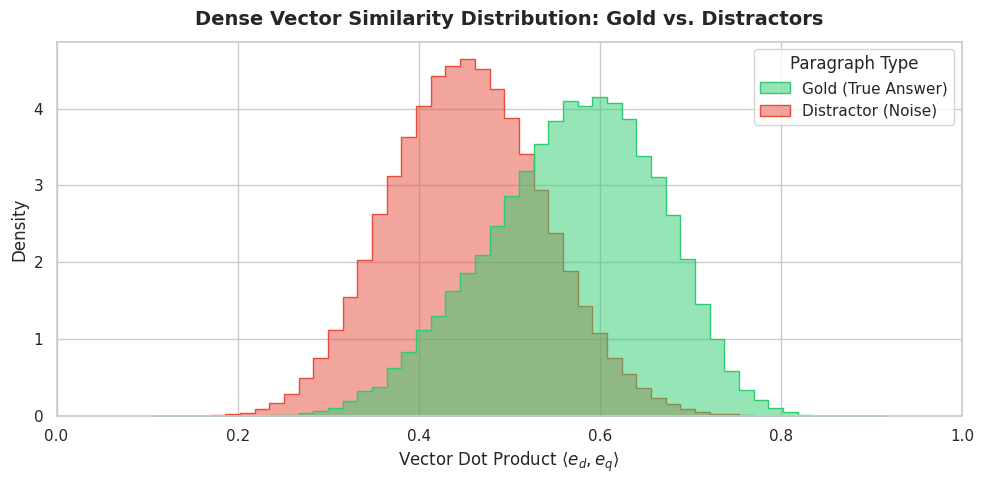

In [16]:
# ---------------------------------------------------------------------------
# PLOT 2: OVERLAPPING DENSITY (GOLD VS. DISTRACTORS)
# ---------------------------------------------------------------------------
df_gold = pd.DataFrame({"Similarity": gold_scores, "Paragraph Type": "Gold (True Answer)"})
df_dist = pd.DataFrame({"Similarity": distractor_scores, "Paragraph Type": "Distractor (Noise)"})
plot_df = pd.concat([df_gold, df_dist], ignore_index=True)

plt.figure(figsize=(10, 5))
sns.histplot(
    data=plot_df, x="Similarity", hue="Paragraph Type", element="step", stat="density",
    common_norm=False, bins=50, palette={"Gold (True Answer)": "#2ecc71", "Distractor (Noise)": "#e74c3c"}, alpha=0.5
)
plt.title("Dense Vector Similarity Distribution: Gold vs. Distractors", fontsize=14, pad=12, weight='bold')
plt.xlabel("Vector Dot Product $\langle e_{d}, e_q \\rangle$", fontsize=12)
plt.ylabel("Density", fontsize=12)
plt.xlim(0, 1.0) # Showing full theoretical range of dot products
plt.tight_layout()
plt.show()